In [ ]:
import serial
import MotoricaInterface as mi ; assert mi.__version__ == '0.0.8' # should be updated each time changes occur
from MotoricaInterface.ubi4 import ubi4_enum_description, ubi4_p2p_high_level_port
from MotoricaInterface.ubi4 import ubi4_p2p_high_level_port_pack
import time
import numpy as np
import matplotlib.pyplot as plt

%matplotlib ipympl

%load_ext autoreload
%autoreload 2


/Users/mike/src/pyMotoricaInterface/MotoricaInterface/ubi4/ubi4_stack.py:17: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm


In [2]:
mi.utils.list_devices()

,device,name,description,hwid,vid,pid,serial_number,location,manufacturer,product,interface
0,/dev/cu.BLTH,cu.BLTH,n/a,n/a,NaN,NaN,None,None,None,None,None
1,/dev/cu.BoseQC35II,cu.BoseQC35II,n/a,n/a,NaN,NaN,None,None,None,None,None
2,/dev/cu.Bluetooth-Incoming-Port,cu.Bluetooth-Incoming-Port,n/a,n/a,NaN,NaN,None,None,None,None,None
3,/dev/cu.usbmodem1234561,cu.usbmodem1234561,Espressif Device,USB VID:PID=303A:4001 SER=123456 LOCATION=20-4,12346.0,16385.0,123456,20-4,Espressif Systems,Espressif Device,None


In [3]:
   
ubi4_stack = mi.ubi4.Ubi4Stack('/dev/cu.usbmodem1234561')
ubi4_stack.initialize_stack()

display(ubi4_stack)

for sub_device in ubi4_stack.sub_devices_array:
    print('--------------SUBDEVICE------------------')
    display(sub_device)

assert "DCE_OMG_MODULE" in [ubi4_enum_description.device_codes_enum(sub_device.DeviceCode).name 
                            for sub_device in ubi4_stack.sub_devices_array], "DCE_OMG_MODULE not found"

--------------------------------
Stopping streaming
Sending: ['0x20', '0x08', '0x00', '0x01', '0x00', '0xbc', '0x00', '0x02']
Should be: [0x20, 0x08, 0x00, 0x01, 0x00, 0x00, 0x00, 0x02]
Streaming stopped
********************************
Serial flushed
Serial flushed
--------------------------------
Requesting first info from the stack
Sending: ['0x00', '0x01', '0x00', '0x02', '0x00', '0x78', '0x00', '0x01', '0x02']
CRC check failed: pack_crc=224, calc_crc=186
FullInitializeConnectionStruct loaded
Full initialize structure:
DeviceName: UBIv4_CPU
DeviceVersion: 1
DeviceSubVersion: 0
DeviceLabel: t
DeviceType: 1
DeviceCode: 1
DeviceAddress: 0
DeviceUUID_Prefix: CPU MODULE
DeviceUUID: 1234567
ParametrsNum: 4
SubDeviceNum: 5
ProgramType: 2
DefaultPort: 0
********************************
--------------------------------
Requesting device parameters
Requesting device parameters: ['0x00', '0x01', '0x00', '0x03', '0x00', '0x31', '0x00', '0x02', '0x00', '0x0a']
CRC check failed: pack_crc=127, ca

UBI4Stack
ser=/dev/cu.usbmodem1234561
DeviceName: UBIv4_CPU
DeviceVersion: 1
DeviceSubVersion: 0
DeviceLabel: t
DeviceType: 1
DeviceCode: 1
DeviceAddress: 0
DeviceUUID_Prefix: CPU MODULE
DeviceUUID: 1234567
ParametrsNum: 4
SubDeviceNum: 5
ProgramType: 2
DefaultPort: 0
5 subdevices found
Parameters:
	(PDCE_SIMPLE_COMMAND:1 bytes)
	(PDCE_ACTION_REQUEST:6 bytes)
	(PDCE_SELECT_PROFILE:1 bytes)
	(PDCE_INTERFECE_ERROR_COUNTER:1 bytes)

--------------SUBDEVICE------------------


DeviceType=37 : DTE_OMG_MULTY_CH
DeviceCode=7 : DCE_OMG_MODULE
DeviceRole=7 : DRE_HAND_OPEN_SENSOR
DeviceVersion=1
DeviceSubVersion=0
DeviceAddress=10
ParametersNum=9
SubDeviceNum=0
DefaultPort=2
Parameters:
	(PDCE_NO_CODE:4 bytes)
	(PDCE_ACTION_REQUEST:6 bytes)
	(PDCE_EMG_CH_1_3_VAL:2 bytes)
	(PDCE_EMG_ENV_E_VAL:8 bytes)
	(PDCE_DMS_OUTPUT:1 bytes)
	(PDCE_OPTIC_LEARNING_DATA:156 bytes)
	(PDCE_OPTIC_CHECKPOINT_DATA_RECEIVER:204 bytes)
	(PDCE_GENERIC_2:6 bytes)
	(PDCE_GENERIC_1:1 bytes)

--------------SUBDEVICE------------------


DeviceType=81 : DTE_BMS
DeviceCode=5 : DCE_BMS
DeviceRole=6 : DRE_BMS
DeviceVersion=1
DeviceSubVersion=0
DeviceAddress=7
ParametersNum=4
SubDeviceNum=0
DefaultPort=1
Parameters:
	(PDCE_BMS_STATUS_COMBINED_PARAM:4 bytes)
	(PDCE_DATE_AND_TIME:8 bytes)
	(PDCE_VIBRO_MOTOR_ACTION:1 bytes)
	(PDCE_GENERIC_9:1 bytes)

... (2 outputs left out)

--------------SUBDEVICE------------------


DeviceType=68 : DTE_DISPLAY_BUTTONS
DeviceCode=6 : DCE_GUI
DeviceRole=2 : DRE_DISPLAY
DeviceVersion=1
DeviceSubVersion=0
DeviceAddress=9
ParametersNum=16
SubDeviceNum=0
DefaultPort=1
Parameters:
	(PDCE_ACTION_REQUEST:6 bytes)
	(PDCE_GESTURE_GROUP:16 bytes)
	(PDCE_SELECT_GESTURE:1 bytes)
	(PDCE_SELECT_PROFILE:1 bytes)
	(PDCE_GLOBAL_FORCE:1 bytes)
	(PDCE_GLOBAL_SENSITIVITY:1 bytes)
	(PDCE_GLOBAL_THRESHOLD:1 bytes)
	(PDCE_OPEN_CLOSE_THRESHOLD:4 bytes)
	(PDCE_BMS_STATUS_COMBINED_PARAM:4 bytes)
	(PDCE_EMG_CH_1_3_VAL:2 bytes)
	(PDCE_EMG_CH_1_3_GAIN:2 bytes)
	(PDCE_EMG_ENV_E_VAL:8 bytes)
	(PDCE_DATE_AND_TIME:8 bytes)
	(PDCE_ENERGY_SAVE_MODE:1 bytes)
	(PDCE_NO_CODE:1 bytes)
	(PDCE_LEFT_RIGHT_HAND_MODE:1 bytes)

--------------SUBDEVICE------------------


DeviceType=34 : DTE_EMG_2CH
DeviceCode=4 : DCE_EMG_SENSE
DeviceRole=8 : DRE_HAND_CLOSE_SENSOR
DeviceVersion=1
DeviceSubVersion=0
DeviceAddress=8
ParametersNum=5
SubDeviceNum=0
DefaultPort=1
Parameters:
	(PDCE_EMG_CH_1_3_VAL:2 bytes)
	(PDCE_GLOBAL_SENSITIVITY:1 bytes)
	(PDCE_EMG_CH_1_3_GAIN:2 bytes)
	(PDCE_EMG_ENV_E_VAL:8 bytes)
	(PDCE_SWITCH_SENSORS:1 bytes)

# Work with optics

In [4]:
# ubi4_stack.stop_parsing_thread()

In [5]:
if ubi4_stack.__run_parsing_thread__:
    ubi4_stack.stop_parsing_thread()

ubi4_stack.start_parsing_thread()
time.sleep(1)

--------------------------------
Starting parsing thread
Parsing thread started successfully
********************************
Serial flushed


In [6]:
ubi4_stack.start_streaming()

--------------------------------
Starting streaming
Sending: ['0x20', '0x08', '0x00', '0x01', '0x00', '0x5e', '0x00', '0x01']
Should be: [0x20, 0x08, 0x00, 0x01, 0x00, 0x00, 0x00, 0x01]
Streaming started
********************************


b''

In [7]:
# push button
ubi4_stack.ser.write(bytes([0x60, 0x80, 0x00, 0x01, 0x00, 0x00, 0x0A, 0x02]))

8

In [8]:
import struct
import socket

teleplotAddr = ("127.0.0.1", 47269)
sock = socket.socket(socket.AF_INET, socket.SOCK_DGRAM)

def sendTelemetry(name, value):
	msg = name+":"+str(value)
	sock.sendto(msg.encode(), teleplotAddr)
     

addresses_devices_map = {subdevice.DeviceAddress: subdevice 
                         for subdevice in ubi4_stack.sub_devices_array}

addresses_names_map = {a: ubi4_enum_description.device_codes_enum(d.DeviceCode).name 
                           for a, d in addresses_devices_map.items()}

addresses_devices_map[0x00] = ubi4_stack 
addresses_names_map[0x00] = ubi4_enum_description.device_codes_enum(1).name

print(addresses_names_map)

ubi4_stack.pack_history.clear()
ubi4_stack.flush_serial()

ubi4_states = {}

_ubi4_state = {}

n_states = 0

while True:
    if not ubi4_stack.__run_parsing_thread__:
        print("Parsing thread is not running")
        break
    
    if n_states > 1000: 
        # early stop
        break

    if len(ubi4_stack.pack_history) > 0:
        pack_ts, pack = ubi4_stack.pack_history.popleft()
        try:
            pack_header, pack_payload = ubi4_p2p_high_level_port.parse_p2p_high_level_port_pack(pack)
        except ubi4_p2p_high_level_port.P2P_PACK_SIZE_MISMATCH_ERROR:
            print(f'Pack size mismatch: {len(pack)}')
            raise Exception(f'Pack size mismatch: {len(pack)}')
            continue
        except Exception as e:
            print(e)
            print(f'Error: {e}')
            continue
    
        if ubi4_enum_description.Command_enum(pack_header['package_code']).name == 'COMPLEX_PARAMETER_TRANSFER':
            print(f'n_states: {n_states: >5}', end = ' '*50 + '\r')
            n_states += 1 
            _ubi4_state = {}
            while len(pack_payload)>0:
                device_address = pack_payload[0]
                device_code_name = addresses_names_map[device_address]

                device_parameter_id = pack_payload[1]
                try:
                    device_parameter_name = ubi4_enum_description.parameter_data_code_enum(ubi4_stack.__device_addresses_map__[device_address].parsed_parameters[device_parameter_id].DataCode).name
                except Exception as e:
                    device_parameter_name = str(ubi4_stack.__device_addresses_map__[device_address].parsed_parameters[device_parameter_id].DataCode)
                    
                vec_index = (device_code_name, device_parameter_name)

                if not vec_index in _ubi4_state:
                    _ubi4_state[vec_index] = {}

                device_parameter_width = ubi4_stack.__device_addresses_map__[device_address].parsed_parameters[device_parameter_id].parameter_size
                # _ubi4_state[vec_index]['width'] = device_parameter_width

                payload_chunk = pack_payload[2:2+device_parameter_width]
                # _ubi4_state[vec_index]['payload_chunk'] = payload_chunk

                pack_values = ubi4_stack.parse_parameter_values(payload_chunk, device_code_name, device_parameter_name)
                # _ubi4_state[vec_index]['pack_values'] = pack_values

                _ubi4_state[vec_index] = pack_values

                pack_payload = pack_payload[2+device_parameter_width:]

            ubi4_states[time.time()] = _ubi4_state.copy()

            if ('DCE_OMG_MODULE', 'PDCE_OPTIC_LEARNING_DATA') in _ubi4_state:
                # ['ts', 'td', 'omg', 'emg', 'bno_rpy', 'bno_acc', 'prb', 'argmax', 'denoize']
                _substate = _ubi4_state[('DCE_OMG_MODULE', 'PDCE_OPTIC_LEARNING_DATA')]
                for i, v in enumerate(_substate['omg']):
                    sendTelemetry(f'omg_learning_data_{i}', v)
                for i, v in enumerate(_substate['emg']):
                    sendTelemetry(f'emg_learning_data{i}', v)
                for i, v in enumerate(_substate['prb']):
                    sendTelemetry(f'prb_{i}', v)
                for i, v in enumerate(_substate['denoize']):
                    sendTelemetry(f'prb_{i}', v)
                    
            # if ('DCE_EMG_SENSE', 'PDCE_EMG_CH_1_3_VAL') in _ubi4_state:
            #     (emg_a, emg_b) = _ubi4_state[('DCE_EMG_SENSE', 'PDCE_EMG_CH_1_3_VAL')]
            #     sendTelemetry('emg_a', emg_a)
            #     sendTelemetry('emg_b', emg_b)      

            if ('DCE_OMG_MODULE', 'PDCE_DMS_OUTPUT') in _ubi4_state:
                dms_output = _ubi4_state[('DCE_OMG_MODULE', 'PDCE_DMS_OUTPUT')]
                sendTelemetry('dms_output', dms_output)                

        else:
            raise Exception(f'Unknown package code: {pack_header["package_code"]}')
                
        
    else:
        time.sleep(0.010)

{10: 'DCE_OMG_MODULE', 7: 'DCE_BMS', 6: 'DCE_FEST_H_AND_F', 9: 'DCE_GUI', 8: 'DCE_EMG_SENSE', 0: 'DCE_CPU_MODULE'}
Serial flushed


KeyboardInterrupt: 

In [9]:
import pandas as pd
df_states = pd.DataFrame(ubi4_states).T
df_states.index.name='timestamp'
df_states.index -= df_states.index[0]
df_states.ffill(inplace=True, axis=0)
df_states.bfill(inplace=True, axis=0)

df_states


,DCE_OMG_MODULE
,PDCE_OPTIC_LEARNING_DATA
timestamp,
0.000000,"{'ts': (219200,), 'td': (3,), 'omg': (4107303...."
0.042477,"{'ts': (219240,), 'td': (3,), 'omg': (4107431...."
0.078482,"{'ts': (219280,), 'td': (3,), 'omg': (4107234...."
0.121951,"{'ts': (219320,), 'td': (3,), 'omg': (4107334...."
0.156958,"{'ts': (219360,), 'td': (3,), 'omg': (4107564...."
...,...
2.996377,"{'ts': (222200,), 'td': (3,), 'omg': (4107264...."
3.039679,"{'ts': (222240,), 'td': (3,), 'omg': (4107419...."


# OMG Raw

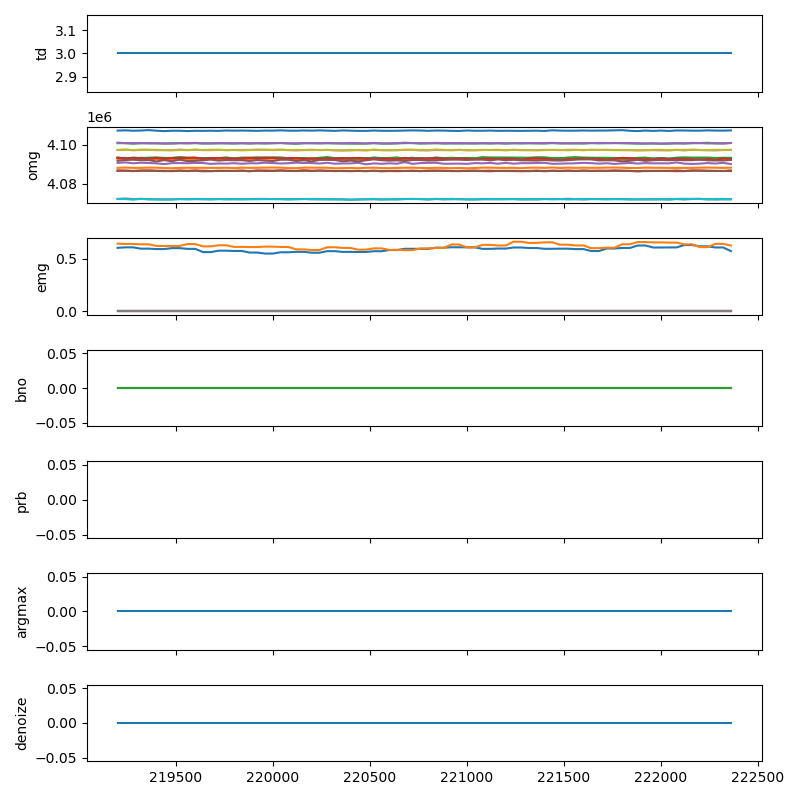

In [10]:
df_omg_raw = pd.DataFrame(list(df_states['DCE_OMG_MODULE']['PDCE_OPTIC_LEARNING_DATA']))
ts = np.concatenate(df_omg_raw['ts'], axis=0)
df_omg_raw.drop(columns=['ts'], inplace=True)

fig, axx = plt.subplots(len(df_omg_raw.columns), 1, sharex=True, figsize=(8, 8))
for ax, col_name in zip(axx, df_omg_raw):
    X = np.stack(df_omg_raw[col_name].values, axis=0)
    ax.plot(ts, X)
    ax.set_ylabel(col_name)

plt.tight_layout()

# Gestures

KeyError: ('DCE_FEST_H_AND_F', 'PDCE_SELECT_GESTURE')

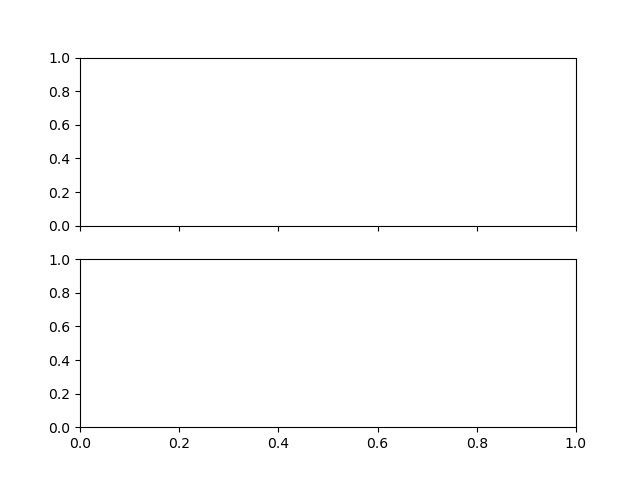

In [14]:
fig, axx = plt.subplots(2, 1,sharex=True)
plt.sca(axx[0])
plt.plot(df_states[('DCE_FEST_H_AND_F', 'PDCE_SELECT_GESTURE')].fillna(-1).values.astype(int))
plt.title('Actions')

plt.sca(axx[1])
plt.plot(df_states[('DCE_OMG_MODULE', 'PDCE_DMS_OUTPUT')].values+0.1, label='DMS output', lw=1)
plt.plot(df_states[('DCE_OMG_MODULE', 'PDCE_OPTIC_LEARNING_DATA')].apply(lambda x: x[-1] if not pd.isna(x) else None).values-0.1, label='Optic learning data', lw=1)
plt.legend()
plt.title('DMS output')


# EMG

In [22]:
emg_states = np.stack(df_states.loc[:, ('DCE_EMG_SENSE', 'PDCE_EMG_CH_1_3_VAL')], axis=0)
# errors = np.stack(df_states.loc[:, ('DCE_CPU_MODULE', 'PDCE_INTERFECE_ERROR_COUNTER')], axis=0)

hmi_states = np.stack(df_states.loc[:, ('DCE_OMG_MODULE', 'PDCE_OPTIC_LEARNING_DATA')], axis=0)
hmi_omg_states = hmi_states[:, :16]
hmi_emg_states = hmi_states[:, 16:18]
hmi_ts_ms = hmi_states[:, 18]
hmi_ts_ms -= hmi_ts_ms[0]
hmi_ts_s = hmi_ts_ms / 1000
hmi_class = hmi_states[:, 19]

fig, axx = plt.subplots(4, 1, figsize=(8, 8))
plt.sca(axx[0])
plt.plot(hmi_ts_s, hmi_omg_states)
# plt.legend(['omg_learning_data_'+str(i) for i in range(16)])

plt.sca(axx[1])
plt.plot(hmi_ts_s, hmi_emg_states)
plt.legend(['emg_float_a', 'emg_float_b'])

plt.sca(axx[2])
# plt.plot(hmi_ts_s, errors)
# plt.legend()

plt.sca(axx[3])
plt.plot(hmi_ts_s, hmi_class)
plt.legend(['hmi_class'])

plt.tight_layout()

plt.figure()
plt.hist(1000*df_states.index.diff().dropna(),bins=np.arange(0,100,0.1));
plt.title('Расстояние между пакетами');
plt.xlabel('Расстояние между пакетами, мс');
plt.ylabel('Количество пакетов');

plt.figure()
plt.hist(np.diff(hmi_ts_ms),bins=np.arange(0,100,0.5)-0.25);
plt.title('Расстояние между пакетами');
plt.xlabel('Расстояние между пакетами, мс');
plt.ylabel('Количество пакетов');

KeyError: ('DCE_EMG_SENSE', 'PDCE_EMG_CH_1_3_VAL')

In [24]:
pack_header, pack_payload = ubi4_p2p_high_level.parse_p2p_high_level_port_pack(pack, check_consistency=False)
pack_header, len(pack_payload)


(OrderedDict([('port', 0),
              ('waiting_answer', 0),
              ('request_type', 0),
              ('brige', 0),
              ('package_code', 9),
              ('package_id', 0),
              ('package_size', 178),
              ('crc', 230),
              ('address', 0)]),
 178)

In [25]:
mi.get_crc(pack_payload, 178)

230

In [145]:
p2p_high_level.parse_p2p_high_level_port_pack(pack, check_consistency=False)

(OrderedDict([('port', 3),
              ('waiting_answer', 0),
              ('request_type', 0),
              ('brige', 0),
              ('package_code', 0),
              ('package_id', 72),
              ('package_size', 0),
              ('crc', 3),
              ('address', 60)]),
 bytearray(b''))

In [100]:
pack_header, pack_payload

(OrderedDict([('port', 0),
              ('waiting_answer', 0),
              ('request_type', 0),
              ('brige', 0),
              ('package_code', 9),
              ('package_id', 0),
              ('package_size', 74),
              ('crc', 32),
              ('address', 0)]),
 bytearray(b'\n\x054\x03|Jl\xbb{J\xe4\xdc{J\xb4?{J\xb4\xe8{J(\xc2{J\x04\xcf{J\x90\xa9{J\xd4\xc7{JXC\xa1J\x0c\xb5}J\xbc\xd3}J\xa8\x84|Jp\xf1\x80J\xa3\xbaiK\xf3MhK\x00\x00\x00\x00\x00\x00\x00\x00'))

In [101]:
72//4

18

In [35]:
pack_header

OrderedDict([('port', 0),
             ('waiting_answer', 0),
             ('request_type', 0),
             ('brige', 0),
             ('package_code', 9),
             ('package_id', 0),
             ('package_size', 406),
             ('crc', 88),
             ('address', 0)])

In [92]:
ubi4_enum_description.device_roles_enum['DRE_OMG'].value

7

In [81]:
ubi4_enum_description.device_types_enum._member_names_

['DTE_UNKNOW',
 'DTE_CPU',
 'DTE_SUB_CPU',
 'DTE_DRIVER',
 'DTE_MOTOR_DRIVER',
 'DTE_MOTOR_DRIVER_MULTY_CH',
 'DTE_SENSOR',
 'DTE_EMG_1CH',
 'DTE_EMG_2CH',
 'DTE_EMG_MULTY_CH',
 'DTE_OMG_SEGMENT',
 'DTE_OMG_MULTY_CH',
 'DTE_OMG_EMG_SEGMENT',
 'DTE_OMG_EMG_MULTY_CH',
 'DTE_STIMULATOR',
 'DTE_HMI',
 'DTE_DISPLAY',
 'DTE_BUTTONS',
 'DTE_SOUNDS',
 'DTE_DISPLAY_BUTTONS',
 'DTE_DISPLAY_SOUNDS',
 'DTE_BUTTONS_SOUNDS',
 'DTE_DISPLAY_BUTTONS_SOUNDS',
 'DTE_TOUCH_DISPLAY',
 'DTE_TOUCH_DISPLAY_SOUNDS',
 'DTE_POWER',
 'DTE_BMS',
 'DTE_ACB',
 'DTE_POWER_CONVERTER',
 'DTE_POWER_ISOLATOR',
 'DTE_POWER_COMBO',
 'DTE_COMBO',
 'DTE_OTHER']

In [79]:
ubi4_enum_description.device_roles_enum['DRE_OMG'].value

7

In [26]:
import pandas as pd

pack_data = []

for p in pack_history:
    try:
        p2p_high_level.check_p2p_pack_consistency(p[1])
    except Exception as e:
        print(f'Error: {e}')
        continue

    pack_header, pack_payload = p2p_high_level.parse_p2p_high_level_port_pack(p[1])
    d_header = dict(pack_header)
    d_header['payload'] = pack_payload
    d_header['ts'] = p[0]
    pack_data.append(d_header)

    print(pack_header, pack_payload)

df_packs = pd.DataFrame(pack_data)
df_packs['ts_diff'] = df_packs['ts'].diff()
df_packs


Error: 
OrderedDict([('port', 0), ('waiting_answer', 0), ('request_type', 0), ('brige', 0), ('package_code', 9), ('package_id', 0), ('package_size', 4), ('crc', 216), ('address', 0)]) bytearray(b'\x08\x00\x01\x00')
OrderedDict([('port', 0), ('waiting_answer', 0), ('request_type', 0), ('brige', 0), ('package_code', 9), ('package_id', 0), ('package_size', 4), ('crc', 28), ('address', 0)]) bytearray(b'\x08\x00\x00\x00')
OrderedDict([('port', 0), ('waiting_answer', 0), ('request_type', 0), ('brige', 0), ('package_code', 9), ('package_id', 0), ('package_size', 4), ('crc', 66), ('address', 0)]) bytearray(b'\x08\x00\x00\x01')
OrderedDict([('port', 0), ('waiting_answer', 0), ('request_type', 0), ('brige', 0), ('package_code', 9), ('package_id', 0), ('package_size', 4), ('crc', 28), ('address', 0)]) bytearray(b'\x08\x00\x00\x00')
OrderedDict([('port', 0), ('waiting_answer', 0), ('request_type', 0), ('brige', 0), ('package_code', 9), ('package_id', 0), ('package_size', 4), ('crc', 142), ('addres

,port,waiting_answer,request_type,brige,package_code,package_id,package_size,crc,address,payload,ts,ts_diff
0,0,0,0,0,9,0,4,216,0,"[8, 0, 1, 0]",1.734035e+09,NaN
1,0,0,0,0,9,0,4,28,0,"[8, 0, 0, 0]",1.734035e+09,7.520163
2,0,0,0,0,9,0,4,66,0,"[8, 0, 0, 1]",1.734035e+09,0.080663
3,0,0,0,0,9,0,4,28,0,"[8, 0, 0, 0]",1.734035e+09,2.639304
4,0,0,0,0,9,0,4,142,0,"[8, 0, 0, 151]",1.734035e+09,0.079805
5,0,0,0,0,9,0,4,180,0,"[8, 0, 0, 239]",1.734035e+09,0.080045
6,0,0,0,0,9,0,4,124,0,"[8, 0, 3, 255]",1.734035e+09,0.079788
7,0,0,0,0,9,0,4,226,0,"[8, 0, 98, 255]",1.734035e+09,0.090066
8,0,0,0,0,9,0,4,231,0,"[8, 0, 67, 255]",1.734035e+09,0.070153
9,0,0,0,0,9,0,4,121,0,"[8, 0, 34, 255]",1.734035e+09,0.079519
